# C02l — Human sentence and word length references
Run top to bottom. Human RAID training documents only; no edits or model generation.

Six primary statistics: mean and population variance (`ddof=0`) of alphabetic words per sentence, characters per sentence, and characters per alphabetic word. Sentence characters include punctuation and internal spaces, but exclude leading/trailing whitespace. Newlines are replaced with spaces, matching the existing detector preprocessing. Only spaCy sentences containing alphabetic words are counted. True word length uses original token spelling (before lowercasing).

The legacy detector ratios `len(normalized_text)/W` and `len(normalized_text)/S` are saved separately: they are not silently substituted for token/span averages. One-sentence variance is numerically zero but excluded from sentence-variance reference quantiles; one-word variance is likewise excluded. These are empirical reference quantiles, **not confidence intervals**. Poetry is measured for description but excluded from editing references.

Updated coverage: a reference must be within a multiplicative factor of 1.25 of the controlled word count. At least 15 eligible documents are required per metric; no distant or cross-genre fallback. This initial tolerance is configurable, not statistically calibrated. Sentence counts are reported, not matched.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import spacy

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
SOURCE = ROOT / 'results/causal/C02j_fz118_residual_30'
OUT = ROOT / 'results/causal/C02l_human_length_references'
OUT.mkdir(parents=True, exist_ok=True)
N_NEAREST = 30
MIN_REFERENCE_N = 15
MAX_LENGTH_FACTOR = 1.25  # eligible human W in [controlled W / 1.25, controlled W * 1.25]
nlp = spacy.load('en_core_web_sm')
METRICS = ['wps_mean','wps_var','cps_mean','cps_var','cpw_mean','cpw_var']
features = pd.read_parquet(BASE / 'fz118_paired_features.parquet')
corpus = pd.read_parquet(BASE / 'paired_corpus.parquet')
assert features.source_id.is_unique and corpus.source_id.is_unique
human_meta = features.loc[(features.dataset == 'raid') & (features.split == 'train') & (features.label == 0), ['source_id','domain']].copy()
human_meta['domain'] = human_meta.domain.astype(str).str.strip().str.lower()
human_meta = human_meta.sort_values('source_id')
texts = corpus.set_index('source_id').text
assert len(human_meta) and human_meta.source_id.isin(texts.index).all()
assert texts.loc[human_meta.source_id].map(lambda x: isinstance(x, str)).all()
print(f'{len(human_meta)} human training documents; parser: {nlp.meta["name"]} {nlp.meta["version"]}')


636 human training documents; parser: core_web_sm 3.8.0


In [2]:
def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        'wps': [sum(t.is_alpha for t in s) for s in sentences],
        'cps': [len(s.text.strip()) for s in sentences],
        'cpw': [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {'W':W, 'S':S, 'C':C,
              'detector_C_over_W': C/W if W else np.nan,
              'detector_C_over_S': C/S if S else np.nan,
              'share_unique_words': len({t.text.lower() for t in tokens})/W if W else np.nan}
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name+'_mean'] = float(a.mean()) if len(a) else np.nan
        result[name+'_var'] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs

def eligible_values(frame, metric):
    if metric in ('wps_var', 'cps_var'):
        frame = frame.loc[frame.S >= 2]
    elif metric == 'cpw_var':
        frame = frame.loc[frame.W >= 2]
    return frame[metric].dropna()

rows, sequences = [], []
records = human_meta.to_dict('records')
normalized = (texts.loc[r['source_id']].replace('\n',' ').replace('\r',' ') for r in records)
for i, (meta, doc) in enumerate(zip(records, nlp.pipe(normalized, batch_size=32)), 1):
    stats, seqs = measure(doc)
    rows.append({**meta, **stats})
    sequences.append({**meta, **seqs})
    if i % 100 == 0: print(f'Measured {i}/{len(records)}')
human = pd.DataFrame(rows)
human.to_csv(OUT / 'human_document_moments.csv', index=False)
with (OUT / 'human_length_sequences.jsonl').open('w') as f:
    for row in sequences: f.write(json.dumps(row)+'\n')

q_levels = [.05,.20,.40,.50,.60,.80,.95]
def summarize(frame, keys):
    result = []
    for key, group in frame.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        for metric in METRICS:
            values = eligible_values(group, metric)
            result.append({**dict(zip(keys,key)), 'metric':metric,
                'n_documents':len(group), 'n_valid':len(values),
                **{f'q{int(q*100):02d}':values.quantile(q) for q in q_levels}})
    return pd.DataFrame(result)
summary = summarize(human, ['domain'])
summary.to_csv(OUT / 'human_genre_quantiles.csv', index=False)
display(summary.round(4))
print('Each observation is a document statistic; documents have equal weight.')


Measured 100/636
Measured 200/636
Measured 300/636
Measured 400/636
Measured 500/636
Measured 600/636


,domain,metric,n_documents,n_valid,q05,q20,q40,q50,q60,q80,q95
0,abstracts,wps_mean,105,105,18.2533,20.4800,22.5651,23.1111,23.6417,25.4200,31.1000
1,abstracts,wps_var,105,105,14.8594,23.8653,47.2974,51.9592,60.9162,96.4627,207.4764
2,abstracts,cps_mean,105,105,125.0400,139.2306,151.6485,154.1429,160.4500,178.8000,213.1500
3,abstracts,cps_var,105,105,484.3704,1156.8400,2070.0027,2405.3333,2722.7429,4263.1223,9186.4640
4,abstracts,cpw_mean,105,105,5.0237,5.3803,5.5306,5.5976,5.6676,5.8750,6.0955
5,abstracts,cpw_var,105,105,7.6925,8.6396,9.2326,9.5454,9.8945,10.4861,11.9095
6,books,wps_mean,84,84,18.0094,19.8410,21.9273,22.6190,23.0727,26.4133,30.0562
7,books,wps_var,84,84,28.5137,48.9539,63.4747,66.4153,77.3547,102.2374,180.7103
8,books,cps_mean,84,84,102.3467,116.4351,130.0792,132.6889,142.1325,155.8400,182.5875
9,books,cps_var,84,84,954.1649,1613.0375,2108.6929,2520.6020,2646.0875,3669.1568,6905.1983


Each observation is a document statistic; documents have equal weight.


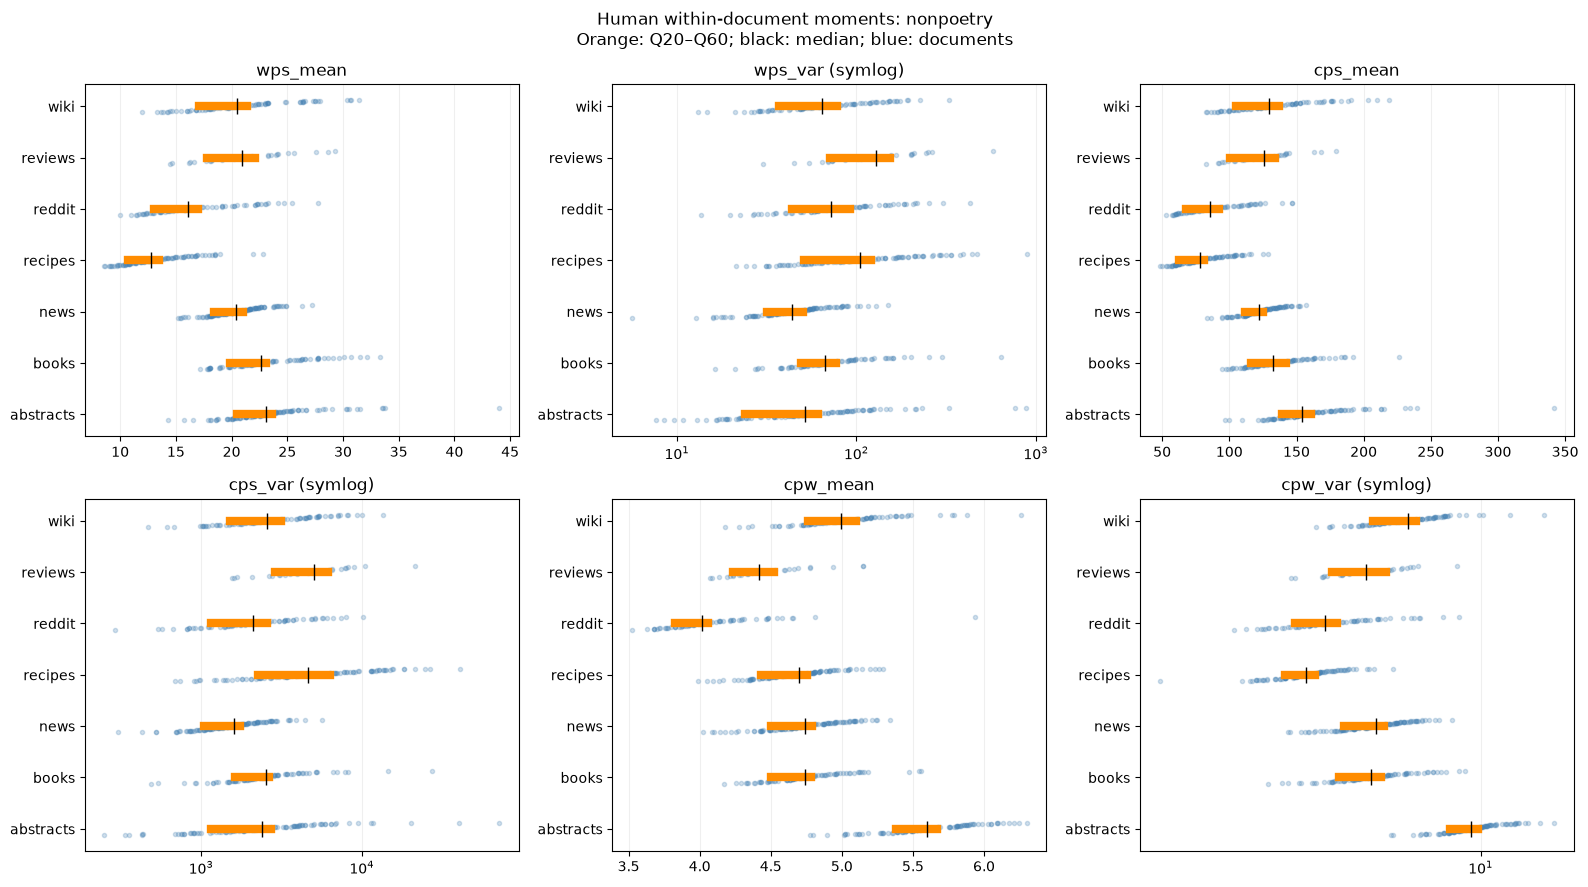

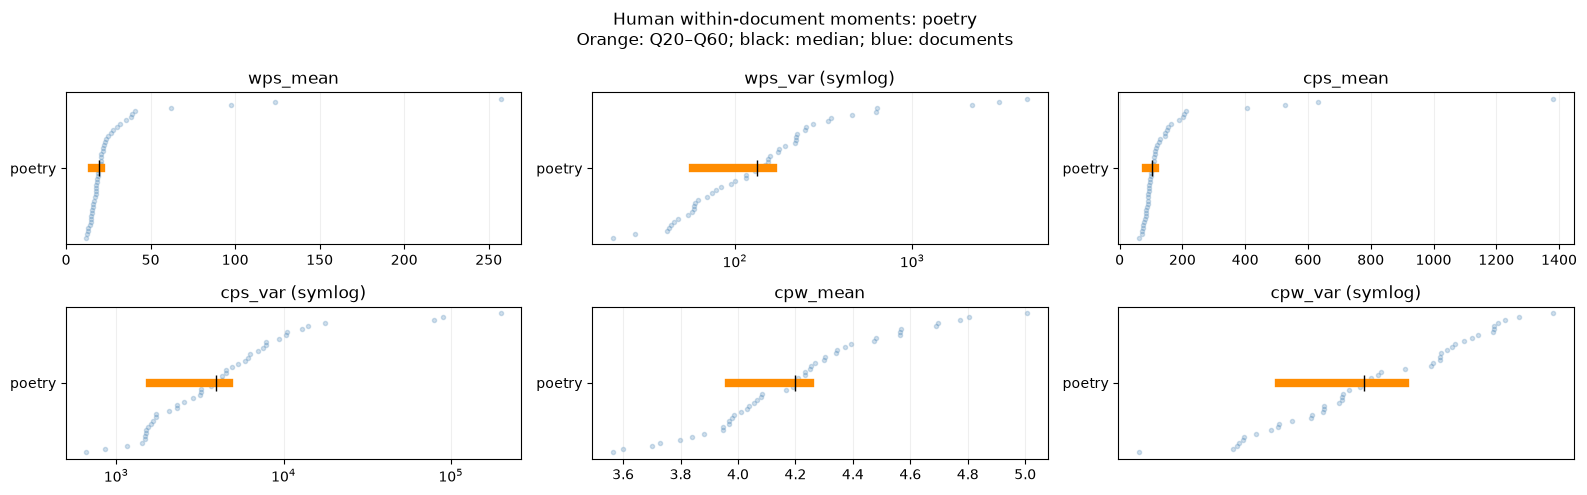

In [3]:
# Poetry separately; symlog variance axes preserve zero while revealing the bulk.
for panel_name, genres in [
    ('nonpoetry', sorted(set(human.domain) - {'poetry'})),
    ('poetry', ['poetry'] if 'poetry' in set(human.domain) else [])]:
    if not genres: continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 9 if panel_name == 'nonpoetry' else 5))
    for ax, metric in zip(axes.flat, METRICS):
        for i, genre in enumerate(genres):
            v = eligible_values(human.loc[human.domain == genre], metric)
            if not len(v): continue
            low, mid, high = v.quantile([.2,.5,.6])
            ax.scatter(v.sort_values(), i+np.linspace(-.12,.12,len(v)),
                       s=9, alpha=.25, color='steelblue')
            ax.plot([low,high], [i,i], color='darkorange', lw=6)
            ax.plot(mid,i, '|', color='black', markersize=12)
        if metric.endswith('_var'):
            ax.set_xscale('symlog', linthresh=1)
        ax.set_yticks(range(len(genres)), genres)
        ax.set_title(metric + (' (symlog)' if metric.endswith('_var') else ''))
        ax.grid(axis='x', alpha=.2)
    fig.suptitle('Human within-document moments: ' + panel_name + '\nOrange: Q20–Q60; black: median; blue: documents')
    fig.tight_layout()
    fig.savefig(OUT / f'human_genre_moments_{panel_name}.png', dpi=180, bbox_inches='tight')
    plt.show()
# Sentence-variance correlations exclude one-sentence documents too.
correlation_input = human.copy()
correlation_input.loc[correlation_input.S < 2, ['wps_var','cps_var']] = np.nan
correlation_input.loc[correlation_input.W < 2, 'cpw_var'] = np.nan
correlation_input.groupby('domain')[METRICS].corr(method='spearman').to_csv(
    OUT / 'human_genre_spearman.csv')


In [4]:
# Match to the actual unique-controlled rewrite length, strictly within genre.
# No pooled fallback. Retain entire six-dimensional human rows for later joint targeting.
manifest = pd.read_csv(SOURCE / 'selection_30.csv')
manifest = manifest.loc[~manifest.domain.astype(str).str.lower().eq('poetry')]
contract = json.loads((SOURCE / 'frozen_contract.json').read_text())
contract_hash = hashlib.sha256(json.dumps(contract,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
matched_rows, bounds_rows, case_rows = [], [], []
for case in manifest.to_dict('records'):
    payload = json.loads((SOURCE / case['case_id'] / 'controlled/state.json').read_text())
    assert payload['contract_hash'] == contract_hash, case['case_id']
    state = payload['state']
    assert state['finished'] and state['status'] == 'completed_eos', case['case_id']
    text = state['committed_text'].replace('\n',' ').replace('\r',' ')
    stats, _ = measure(nlp(text))
    genre = str(case['domain']).strip().lower()
    pool = human.loc[(human.domain == genre) & (human.W > 0)].copy()
    pool['log_length_distance'] = abs(np.log(pool.W) - np.log(max(1,stats['W'])))
    eligible_pool = pool.loc[pool.log_length_distance <= np.log(MAX_LENGTH_FACTOR) + 1e-12]
    refs = eligible_pool.sort_values(['log_length_distance','source_id']).head(N_NEAREST)
    refs.insert(0, 'case_id', case['case_id'])
    matched_rows.extend(refs.to_dict('records'))
    case_rows.append({'case_id':case['case_id'], 'domain':genre, **stats,
        'genre_pool_n':len(pool), 'length_eligible_n':len(eligible_pool),
        'length_match_supported':len(refs) >= MIN_REFERENCE_N,
        'reference_S_min':refs.S.min(), 'reference_S_median':refs.S.median(), 'reference_S_max':refs.S.max(),
        'reference_n':len(refs), 'reference_W_min':refs.W.min(), 'reference_W_max':refs.W.max(),
        'max_log_length_distance':refs.log_length_distance.max()})
    for metric in METRICS:
        v = eligible_values(refs, metric)
        reference_supported = len(v) >= MIN_REFERENCE_N
        controlled_valid = bool(np.isfinite(stats[metric])) and (stats['S'] >= 2 if metric in ('wps_var','cps_var') else stats['W'] >= 2 if metric == 'cpw_var' else True)
        supported = reference_supported and controlled_valid
        if not controlled_valid: status = 'undefined_or_too_few_units'
        elif not reference_supported: status = 'insufficient_length_matched_references'
        elif stats[metric] < v.quantile(.2): status = 'below_q20'
        elif stats[metric] > v.quantile(.6): status = 'above_q60'
        else: status = 'within_q20_q60'
        bounds_rows.append({'case_id':case['case_id'],'domain':genre,'metric':metric,
            'controlled_value':stats[metric], 'reference_n':len(v), 'reference_supported':reference_supported,
            'controlled_valid':controlled_valid, 'supported':supported, 'status':status,
            **{f'q{int(q*100):02d}':v.quantile(q) if reference_supported else np.nan for q in q_levels}})
case_summary = pd.DataFrame(case_rows)
matched = pd.DataFrame(matched_rows)
bounds = pd.DataFrame(bounds_rows)
case_summary.to_csv(OUT / 'controlled_reference_coverage.csv', index=False)
matched.to_csv(OUT / 'matched_human_joint_moments.csv', index=False)
bounds.to_csv(OUT / 'matched_human_quantiles.csv', index=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(case_summary.round(3))
    display(bounds.pivot(index='case_id', columns='metric', values='status').reindex(columns=METRICS))
    display(bounds.round(4))
(OUT / 'measurement_contract.json').write_text(json.dumps({
    'spacy_version':spacy.__version__, 'parser_meta':nlp.meta,
    'variance_ddof':0, 'human_split':'raid/train/label=0',
    'sentence_selection':'spaCy sentences with alphabetic words',
    'cps':'len(sentence.text.strip()), including internal spaces and punctuation',
    'cpw':'len(original alphabetic token.text)', 'normalize':'replace CR and LF with spaces',
    'reference_selection':'same genre, nearest log alphabetic word count, source_id tie-break',
    'max_length_factor':MAX_LENGTH_FACTOR, 'nearest_n':N_NEAREST, 'minimum_valid_n':MIN_REFERENCE_N,
    'source_contract_hash':contract_hash,
    'human_source_ids':human.source_id.tolist()
}, indent=2, default=str))
print('Saved measurements and plots to:', OUT)
print('No editing targets have been enforced. Review genre, length coverage, and joint rows first.')


,case_id,domain,W,S,C,detector_C_over_W,detector_C_over_S,share_unique_words,wps_mean,wps_var,cps_mean,cps_var,cpw_mean,cpw_var,genre_pool_n,length_eligible_n,length_match_supported,reference_S_min,reference_S_median,reference_S_max,reference_n,reference_W_min,reference_W_max,max_log_length_distance
0,raid_residual_01,abstracts,69,4,451,6.536,112.750,0.739,17.250,4.688,112.000,342.500,5.435,7.637,105,0,False,NaN,NaN,NaN,0,NaN,NaN,NaN
1,raid_residual_02,books,105,4,710,6.762,177.500,0.676,26.250,82.688,176.750,1922.688,5.590,8.108,84,0,False,NaN,NaN,NaN,0,NaN,NaN,NaN
2,raid_residual_03,news,218,11,1285,5.894,116.818,0.578,19.818,13.785,115.000,275.455,4.651,6.759,117,40,True,8.0,11.0,16.0,30,183.0,261.0,0.180
3,raid_residual_05,recipes,302,21,1992,6.596,94.857,0.460,14.381,95.379,93.333,4878.413,4.960,5.051,99,51,True,14.0,21.5,30.0,30,259.0,347.0,0.154
4,raid_residual_06,reddit,99,8,634,6.404,79.250,0.687,12.375,20.484,78.125,720.609,5.101,7.768,71,1,False,5.0,5.0,5.0,1,121.0,121.0,0.201
5,raid_residual_07,reviews,240,11,1398,5.825,127.091,0.608,21.818,21.421,125.818,735.421,4.550,5.614,28,11,False,8.0,11.0,16.0,11,210.0,266.0,0.134
6,raid_residual_08,wiki,135,7,848,6.281,121.143,0.630,19.286,49.347,120.000,1931.714,4.904,7.569,86,14,False,6.0,8.0,12.0,14,149.0,166.0,0.207
7,raid_residual_09,abstracts,145,6,1003,6.917,167.167,0.745,24.167,33.806,166.333,1917.889,5.752,9.111,105,64,True,4.0,7.0,8.0,30,130.0,164.0,0.123
8,raid_residual_10,books,263,12,1615,6.141,134.583,0.589,21.917,25.910,133.417,1128.243,4.962,7.436,84,45,True,8.0,11.0,16.0,30,230.0,298.0,0.134
9,raid_residual_11,news,113,6,715,6.327,119.167,0.690,18.833,28.472,117.500,427.250,4.894,6.803,117,2,False,6.0,6.0,6.0,2,124.0,127.0,0.117


metric,wps_mean,wps_var,cps_mean,cps_var,cpw_mean,cpw_var
case_id,,,,,,
raid_residual_01,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references
raid_residual_02,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references
raid_residual_03,within_q20_q60,below_q20,within_q20_q60,below_q20,within_q20_q60,above_q60
raid_residual_05,within_q20_q60,within_q20_q60,above_q60,within_q20_q60,above_q60,above_q60
raid_residual_06,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references
raid_residual_07,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references
raid_residual_08,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references,insufficient_length_matched_references
raid_residual_09,above_q60,within_q20_q60,above_q60,within_q20_q60,within_q20_q60,within_q20_q60
raid_residual_10,within_q20_q60,below_q20,within_q20_q60,below_q20,above_q60,above_q60


,case_id,domain,metric,controlled_value,reference_n,reference_supported,controlled_valid,supported,status,q05,q20,q40,q50,q60,q80,q95
0,raid_residual_01,abstracts,wps_mean,17.2500,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,raid_residual_01,abstracts,wps_var,4.6875,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,raid_residual_01,abstracts,cps_mean,112.0000,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,raid_residual_01,abstracts,cps_var,342.5000,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,raid_residual_01,abstracts,cpw_mean,5.4348,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,raid_residual_01,abstracts,cpw_var,7.6371,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,raid_residual_02,books,wps_mean,26.2500,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,raid_residual_02,books,wps_var,82.6875,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,raid_residual_02,books,cps_mean,176.7500,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,raid_residual_02,books,cps_var,1922.6875,0,False,True,False,insufficient_length_matched_references,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved measurements and plots to: ../results/causal/C02l_human_length_references
No editing targets have been enforced. Review genre, length coverage, and joint rows first.


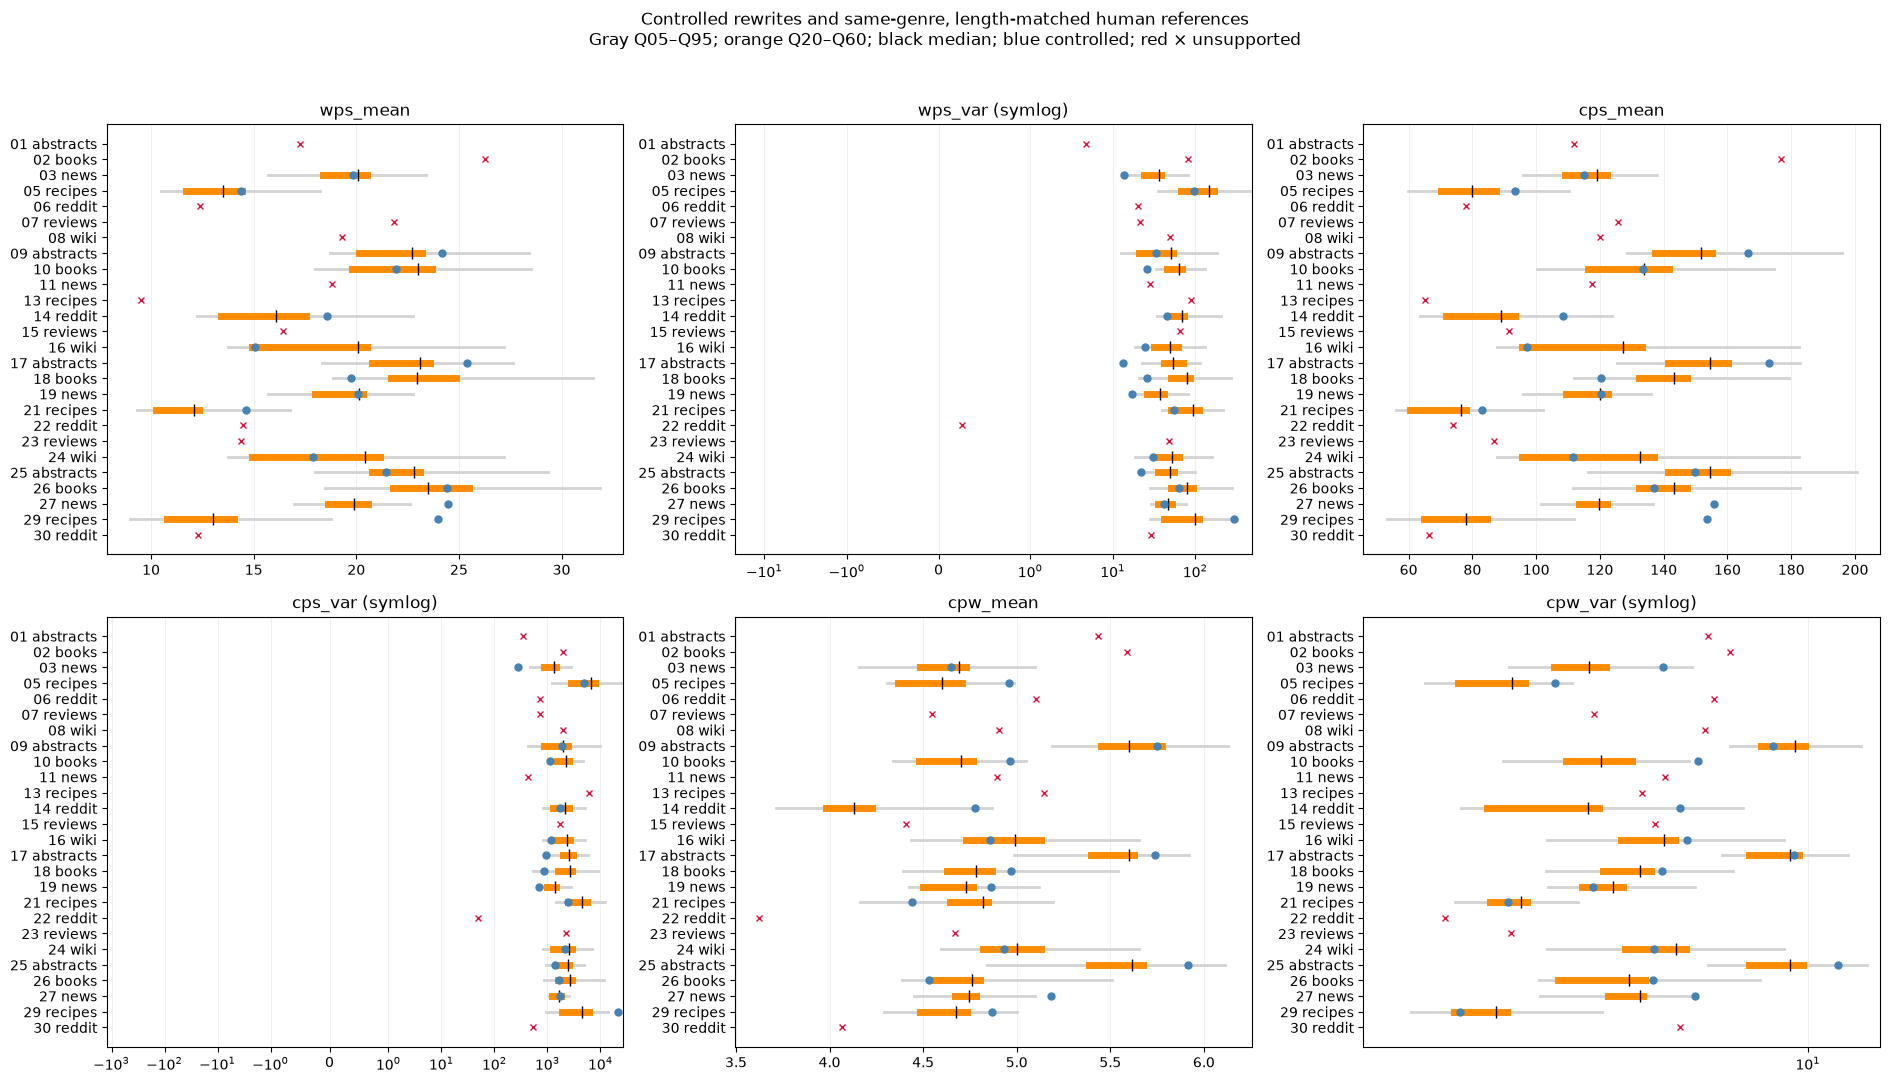

Coverage: 15 / 26 cases have at least 15 human documents within the length limit.
Q20–Q60 is retained for comparison with earlier experiments, not a validated universal acceptance band.


In [5]:
# All controlled values vs their own matched bands. Unsupported rows get no band.
case_ids = case_summary.case_id.tolist()
fig, axes = plt.subplots(2, 3, figsize=(19, max(11, .42*len(case_ids))))
for ax, metric in zip(axes.flat, METRICS):
    table = bounds.loc[bounds.metric == metric].set_index('case_id').reindex(case_ids)
    for i, (case_id, row) in enumerate(table.iterrows()):
        if row.reference_supported:
            ax.plot([row.q05,row.q95], [i,i], color='lightgray', lw=2)
            ax.plot([row.q20,row.q60], [i,i], color='darkorange', lw=5)
            ax.plot(row.q50,i,'|',color='black',markersize=9)
        if np.isfinite(row.controlled_value):
            ax.plot(row.controlled_value,i, 'o' if row.supported else 'x',
                    color='steelblue' if row.supported else 'crimson',markersize=5)
    labels = [f"{c.replace('raid_residual_', '')} {case_summary.set_index('case_id').loc[c,'domain']}" for c in case_ids]
    ax.set_yticks(range(len(case_ids)), labels)
    ax.invert_yaxis()
    if metric.endswith('_var'): ax.set_xscale('symlog',linthresh=1)
    ax.set_title(metric + (' (symlog)' if metric.endswith('_var') else ''))
    ax.grid(axis='x',alpha=.2)
fig.suptitle('Controlled rewrites and same-genre, length-matched human references\n'
             'Gray Q05–Q95; orange Q20–Q60; black median; blue controlled; red × unsupported')
fig.tight_layout(rect=[0,0,1,.96])
fig.savefig(OUT / 'controlled_vs_matched_human_moments.png',dpi=180,bbox_inches='tight')
plt.show()
print('Coverage:', int(case_summary.length_match_supported.sum()), '/', len(case_summary),
      'cases have at least', MIN_REFERENCE_N, 'human documents within the length limit.')
print('Q20–Q60 is retained for comparison with earlier experiments, not a validated universal acceptance band.')
